In [1]:
from langchain_community.document_loaders import TextLoader, DirectoryLoader
from langchain_openai import OpenAIEmbeddings,ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_chroma import Chroma 
from pathlib import Path
from dotenv import load_dotenv

In [2]:
!pip install langchain_chroma


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Loading the keys
load_dotenv()

True

In [3]:
llm=ChatOpenAI(model="gpt-5-mini")
embedder=OpenAIEmbeddings(model="text-embedding-3-small",dimensions=1024)

In [4]:
#Loading the transcripts
loader=DirectoryLoader(path=Path("./data/cleaned"),loader_cls=TextLoader,show_progress=True)

docs=loader.load()

100%|██████████| 14/14 [00:00<00:00, 777.88it/s]


In [6]:
docs[0].page_content

"Pakistan, Ahmedabad, Patna, Dheradoon, Subodh, where are you from? I am from Dheradoon too.\nYou are from Kharrawala, you are from Kharwala, I am from Miawala\nCome on, perfect\nOkay, let's begin\nFirst of all, I will introduce myself\nHas anyone seen me or taken any course of mine before?\nAnyone? Yes or no please?\nOkay, fine\nNo worries, let me tell you about myself\nI am Ajay, I belong to Uttarakhand\nAnd I have been working with CampusX for the last two years\nI am working on the Data Analytics and AI part on CampusX\nAnd in the last two years, I have delivered multiple courses like\nOLAMA, Data Analytics, Mentorship Program, Gemini, Power BI and many more\nAnd I will be taking most of your AI Pulse sessions\nRight? So currently, I am working with CampusX\nAnd I am doing my doctorate in frugal AI\nNow, coming to the session\nToday's session is going to be on AI Pulse\nWhat are we going to do in this session?\nIn this session, we are going to talk about\nWhat are we going to do in

In [5]:
#Chunk the test
chunker= RecursiveCharacterTextSplitter(chunk_size=500,chunk_overlap=50)

chunks=chunker.split_documents(docs)
print(chunks[0].page_content)

Pakistan, Ahmedabad, Patna, Dheradoon, Subodh, where are you from? I am from Dheradoon too.
You are from Kharrawala, you are from Kharwala, I am from Miawala
Come on, perfect
Okay, let's begin
First of all, I will introduce myself
Has anyone seen me or taken any course of mine before?
Anyone? Yes or no please?
Okay, fine
No worries, let me tell you about myself
I am Ajay, I belong to Uttarakhand
And I have been working with CampusX for the last two years


In [14]:
print(chunks)

[Document(metadata={'source': 'data\\cleaned\\1.txt'}, page_content="Pakistan, Ahmedabad, Patna, Dheradoon, Subodh, where are you from? I am from Dheradoon too.\nYou are from Kharrawala, you are from Kharwala, I am from Miawala\nCome on, perfect\nOkay, let's begin\nFirst of all, I will introduce myself\nHas anyone seen me or taken any course of mine before?\nAnyone? Yes or no please?\nOkay, fine\nNo worries, let me tell you about myself\nI am Ajay, I belong to Uttarakhand\nAnd I have been working with CampusX for the last two years"), Document(metadata={'source': 'data\\cleaned\\1.txt'}, page_content="I am working on the Data Analytics and AI part on CampusX\nAnd in the last two years, I have delivered multiple courses like\nOLAMA, Data Analytics, Mentorship Program, Gemini, Power BI and many more\nAnd I will be taking most of your AI Pulse sessions\nRight? So currently, I am working with CampusX\nAnd I am doing my doctorate in frugal AI\nNow, coming to the session\nToday's session is 

In [6]:
#Vector store:
vs=Chroma(collection_name="rag-demo",embedding_function=embedder,
          persist_directory=Path("./saved_embeddings").as_posix())

#add documents
# vs.add_documents(chunks)

In [20]:
#Create a retriever

retriever=vs.as_retriever(search_kwargs={"k":3})
retrieved_doc=retriever.invoke("What is LLMOps?")
print(retrieved_doc)

[Document(id='7517c84d-941e-4531-aed2-268b6f6faf3d', metadata={'source': 'data\\cleaned\\3.txt'}, page_content="There is a definition here too.\nLet's read it.\nSo, what is the definition of LLM Ops?\nIt stands for Large Language Model Operations.\nWhat is LLM?\nIt is a large language model.\nAnd the entire field around its operations\nhas evolved.\nAnd refers to the specialized practices\nand workflows\nthat speed development, deployment\nand management of AI models\nthroughout their complete life cycle.\nAgain, let's copy this definition too.\nLet's copy this definition too.\nI am showing you different versions."), Document(id='84041994-5782-4e54-873d-c0e20c6361ff', metadata={'source': 'data\\cleaned\\4.txt'}, page_content='LLMs\nthat is why it is called LLM ops\nit is very basic\nbut here what is this ops part\nwhat is this ops part\nand where did this ops part come from\nthis ops part basically came from\nyour DevOps\nso these two fields\nML ops and LLM ops\nthey evolved\nfrom your

In [8]:
from langgraph.graph import StateGraph, START, END
from typing import Literal, TypedDict

c:\PYTHON 10\lib\site-packages\langgraph\cache\base\__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


In [9]:
class RAGSTATE(TypedDict):
    
    query: str
    retrieved_doc: list[Document]
    context: str
    prompt: ChatPromptTemplate
    response: str

In [10]:
def retrieve(state: RAGSTATE)->dict:
    #Fetch your query
    query=state["query"]
    #Create your retriever
    retrieved_doc= retriever.invoke(query) # You will receive your 3 most valid docs
    
    context= "\n\n".join([doc.page_content for doc in retrieved_doc])
    
    return {"retrievd_context": retrieved_doc,
            
            "context": context}

In [11]:
def augmentation(state: RAGSTATE)-> dict:
    
    prompt=ChatPromptTemplate.from_messages(
        
        [
            
            ("system","""You are a helful assistent. Answer the user's query based on given context only. If you cant find the context, 
             just say I dont know. Do not add any preamble in response"""),
            
            ("human", "context: {context}\n\nquery:{query}")
        ]
        
    )
    
    return {"prompt":prompt}

In [12]:
from langchain_core.output_parsers import StrOutputParser

In [13]:
def generation(state: RAGSTATE)-> dict:
    
    query=state["query"]
    context=state["context"]
    prompt=state["prompt"]
    
    rag_chain= prompt | llm | StrOutputParser()
    
    response=rag_chain.invoke({"context":context,"query":query})
    
    return {"response": response}

In [14]:
#Create graph
graph_build=StateGraph(RAGSTATE)

graph_build.add_node("retrieve",retrieve)
graph_build.add_node("augmentation",augmentation)
graph_build.add_node("generation",generation)

graph_build.add_edge(START,"retrieve")
graph_build.add_edge("retrieve","augmentation")
graph_build.add_edge("augmentation","generation")
graph_build.add_edge("generation",END)

graph=graph_build.compile()

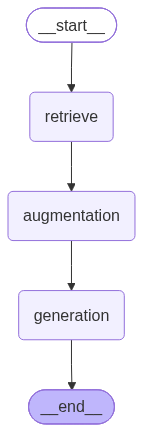

In [17]:
graph

In [15]:
result=graph.invoke({"query":"What is LLMOps?"})
print(result)

{'query': 'What is LLMOps?', 'context': "There is a definition here too.\nLet's read it.\nSo, what is the definition of LLM Ops?\nIt stands for Large Language Model Operations.\nWhat is LLM?\nIt is a large language model.\nAnd the entire field around its operations\nhas evolved.\nAnd refers to the specialized practices\nand workflows\nthat speed development, deployment\nand management of AI models\nthroughout their complete life cycle.\nAgain, let's copy this definition too.\nLet's copy this definition too.\nI am showing you different versions.\n\nLLMs\nthat is why it is called LLM ops\nit is very basic\nbut here what is this ops part\nwhat is this ops part\nand where did this ops part come from\nthis ops part basically came from\nyour DevOps\nso these two fields\nML ops and LLM ops\nthey evolved\nfrom your\nDevOps\nso if I explain it in hierarchy\nor in lineage\nthen you can understand it in this way\nthat first it was your DevOps\nfrom that\nnext evolution came\nwhen your machine lea

In [18]:
print(result.get("retrieved_doc"))

None


In [20]:
result["context"]

"There is a definition here too.\nLet's read it.\nSo, what is the definition of LLM Ops?\nIt stands for Large Language Model Operations.\nWhat is LLM?\nIt is a large language model.\nAnd the entire field around its operations\nhas evolved.\nAnd refers to the specialized practices\nand workflows\nthat speed development, deployment\nand management of AI models\nthroughout their complete life cycle.\nAgain, let's copy this definition too.\nLet's copy this definition too.\nI am showing you different versions.\n\nLLMs\nthat is why it is called LLM ops\nit is very basic\nbut here what is this ops part\nwhat is this ops part\nand where did this ops part come from\nthis ops part basically came from\nyour DevOps\nso these two fields\nML ops and LLM ops\nthey evolved\nfrom your\nDevOps\nso if I explain it in hierarchy\nor in lineage\nthen you can understand it in this way\nthat first it was your DevOps\nfrom that\nnext evolution came\nwhen your machine learning algorithms came\nthen ML ops came\